# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 02 — Can it grade?

A deferral rule is only useful if the grader underneath is competent. This notebook checks that,
and nothing else.



### Setup

Mount Drive so results survive a disconnect, then load the module.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPU:", len(gpus))
if not gpus:
    print("  !! No GPU. Runtime > Change runtime type > T4 GPU, then re-run.")

TF 2.21.0 | GPU: 1


In [ ]:
import os, sys, json, time
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # written by notebook 00, found via PROJECT on sys.path
from evia_knee import Config


if IN_COLAB and not os.path.isdir("/content/knee"):
    !pip -q install kaggle
    E.download_kaggle("knee", "/content/knee")
root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

print("task      :", "knee OA, Kellgren-Lawrence grade 0-4")
print("grades    :", E.GRADE_NAMES)
print("decision  : KL >=", E.OA_THRESHOLD, "=", E.OA_NAME)

# One config object drives everything. Changing a field here changes the experiment.
CFG = Config(
    img_size=224,                  # the radiographs are native ~224 px; upsampling adds nothing
    preprocess="clahe",
    backbone="densenet121",        # full ImageNet DenseNet-121 + EvIA side branch
    widths=(256, 320),             # EvIA branch blocks at 14x14 and 7x7
    global_branch="window",        # EvIA-W
    gate="vacuity",                # parameter-free gate
    operator="evi",
    head="ordinal",
    epochs=60,                     # cosine schedule: every run trains exactly 60 epochs
    batch_size=32,                 # 224 px radiographs leave room for a large batch
    seeds=(42, 43, 44, 45, 46),    # set to (42,) for a quick first pass
    out_dir=os.path.join(PROJECT, "results"),
)
os.makedirs(CFG.out_dir, exist_ok=True)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


### Data

In [ ]:
ds = E.load_knee(cfg=CFG, seed=42)
idx = ds["idx"]
print(f"{ds['name']}: {len(ds['y'])} images")
print("  grades    :", np.bincount(ds["y"], minlength=5))
print(f"  definite OA : {(ds['y']>=E.OA_THRESHOLD).sum()} "
      f"({(ds['y']>=E.OA_THRESHOLD).mean():.1%})")

# Decoded once into uint8 arrays and cached. A restarted session reloads in seconds.
data = {k: E.cached_split(ds["paths"][idx[k]], ds["y"][idx[k]], CFG, "knee_" + k, CACHE)
        for k in ("train", "val", "test")}
Xte, Yte = data["test"]
print(" ", {k: f"{v[0].shape} {v[0].dtype}" for k, v in data.items()})

  using the dataset's own train/val/test split
Knee OA (KL 0-4): 9786 images
  grades    : [3857 1770 2578 1286  295]
  definite OA : 4159 (42.5%)
  knee_train: loaded from cache
  knee_val: loaded from cache
  knee_test: loaded from cache
  {'train': '(5778, 224, 224, 3) uint8', 'val': '(826, 224, 224, 3) uint8', 'test': '(1656, 224, 224, 3) uint8'}


### Model

Pretrained DenseNet-121 (whole network). Its 14×14 map → 2 EvIA blocks (14×14, then 7×7) → pooled,
concatenated with the backbone's pooled 7×7 features → ordinal evidential head. Each EvIA block is a token mixer followed by a channel-mixing
FFN. In the token mixer a local evidential-involution path and a windowed-attention path are
mixed by a gate with no learned parameters:

$$g = \frac{1}{1+u}, \qquad Z = g\,Y^{\rm local} + (1-g)\,Y^{\rm global}$$

High evidence (low $u$) → trust the local path. Low evidence → lean on global context.

All models, EvIA-KL and baselines alike: ImageNet weights frozen for 2 warm-up epochs, then
trained at 0.1× the learning rate of new layers; square-root class weights; the epoch with the
best validation QWK is kept; grades are the median of the predictive distribution; test images
are averaged with their left-right mirror; each grade boundary is recalibrated on the validation split.

In [ ]:
m = E.EvIAKL(CFG); _ = m(tf.zeros([1, CFG.img_size, CFG.img_size, 3]))
print(f"EvIA-KL        {E.count_params(m):>10,} params  (hybrid)")
del m; keras.backend.clear_session()
m = E.EvIAKL(CFG.copy(backbone="scratch", widths=(64, 128, 256, 320)))
_ = m(tf.zeros([1, CFG.img_size, CFG.img_size, 3]))
print(f"EvIA-KL        {E.count_params(m):>10,} params  (scratch)")
del m; keras.backend.clear_session()

for n in ["mobilenetv3s", "efficientnetb0", "densenet121", "resnet50"]:
    b = E.build_baseline(n, CFG)
    print(f"  {n:14s} {E.count_params(b):>10,}")
    del b; keras.backend.clear_session()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EvIA-KL         8,724,104 params  (hybrid)
EvIA-KL         1,743,592 params  (scratch)
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  mobilenetv3s      929,893
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  efficientnetb0  4,013,953
  densenet121     6,958,981
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
  resnet50       23,544,837


### Train

Five seeds. Predictions are saved so notebooks 03 and 04 need not retrain.

In [ ]:
rows = []
for s in CFG.seeds:
    f = os.path.join(CFG.out_dir, f"preds_eviakl_seed{s}.npz")

    if os.path.exists(f):                      # resume: Colab sessions drop mid-run
        print(f"--- seed {s}: already done, loading ---")
        z = np.load(f); p, u, ur = z["p"], z["u"], z["ur"]
    else:
        print(f"--- seed {s} ---")
        m, _ = E.train_model(data, CFG, s, verbose=1)
        p, u, ur, extra = E.predict_calibrated(m, data, CFG)      # val-fitted boundaries
        np.savez(f, p=p, u=u, ur=ur, y=Yte, **extra)  # save now, before anything can crash
        del m; keras.backend.clear_session()

    r = E.evaluate(p, u, ur, Yte, CFG, tag="EvIA-KL"); r["seed"] = s; rows.append(r)
    print(f"    QWK {r['qwk']:.3f} | acc {r['accuracy']:.3f} | OA-AUC {r['oa_auc']:.3f}")

MAIN = pd.DataFrame(rows)
MAIN.to_csv(os.path.join(CFG.out_dir, "grading_evia.csv"), index=False)
print(MAIN[["seed","qwk","accuracy","macro_f1","oa_auc"]].round(3).to_string(index=False))

--- seed 42: already done, loading ---
    QWK 0.838 | acc 0.681 | OA-AUC 0.938
--- seed 43: already done, loading ---
    QWK 0.847 | acc 0.667 | OA-AUC 0.941
--- seed 44: already done, loading ---
    QWK 0.842 | acc 0.652 | OA-AUC 0.937
--- seed 45: already done, loading ---
    QWK 0.728 | acc 0.586 | OA-AUC 0.892
--- seed 46: already done, loading ---
    QWK 0.848 | acc 0.665 | OA-AUC 0.938
 seed   qwk  accuracy  macro_f1  oa_auc
   42 0.838     0.681     0.676   0.938
   43 0.847     0.667     0.675   0.941
   44 0.842     0.652     0.658   0.937
   45 0.728     0.586     0.430   0.892
   46 0.848     0.665     0.678   0.938


### Scratch control

The same EvIA neck and ordinal head on the original randomly initialised stem, with no pretrained
weights. It shows what the EfficientNet-B0 trunk contributes, and keeps the earlier result on record.
Three seeds, like the baselines.

In [ ]:
CFG_SCRATCH = CFG.copy(backbone="scratch", widths=(64, 128, 256, 320))
srows = []
for s in CFG.seeds[:3]:
    f = os.path.join(CFG.out_dir, f"preds_eviakl_scratch_seed{s}.npz")
    if os.path.exists(f):
        print(f"--- scratch seed {s}: cached ---")
        z = np.load(f); p, u, ur = z["p"], z["u"], z["ur"]
    else:
        print(f"--- scratch seed {s} ---")
        m, _ = E.train_model(data, CFG_SCRATCH, s, verbose=1)
        p, u, ur, extra = E.predict_calibrated(m, data, CFG_SCRATCH)
        np.savez(f, p=p, u=u, ur=ur, y=Yte, **extra)
        del m; keras.backend.clear_session()
    r = E.evaluate(p, u, ur, Yte, CFG_SCRATCH, tag="EvIA-KL scratch"); r["seed"] = s; srows.append(r)
    print(f"    QWK {r['qwk']:.3f} | acc {r['accuracy']:.3f} | OA-AUC {r['oa_auc']:.3f}")

SCR = pd.DataFrame(srows)
SCR.to_csv(os.path.join(CFG.out_dir, "grading_scratch.csv"), index=False)

--- scratch seed 42: cached ---
    QWK 0.007 | acc 0.198 | OA-AUC 0.530
--- scratch seed 43: cached ---
    QWK 0.000 | acc 0.179 | OA-AUC 0.546
--- scratch seed 44: cached ---
    QWK 0.000 | acc 0.179 | OA-AUC 0.585


### Baselines

Same splits, augmentation, class weights, optimiser, warm-up, stopping rule, decoding, test-time flip and boundary recalibration — only the network differs.

In [ ]:
brows = []
for name in ["mobilenetv3s", "efficientnetb0", "densenet121", "resnet50"]:
    for s in CFG.seeds[:3]:                    # 3 seeds keeps baseline cost reasonable
        f = os.path.join(CFG.out_dir, f"preds_{name}_seed{s}.npz")
        if os.path.exists(f):
            z = np.load(f); p, u, ur = z["p"], z["u"], z["ur"]
            print(f"--- {name} seed {s}: cached ---")
        else:
            print(f"--- {name} seed {s} ---")
            bm = E.train_baseline(data, name, CFG, s, verbose=0)
            p, u, ur, extra = E.predict_calibrated(bm, data, CFG, baseline=True)
            np.savez(f, p=p, u=u, ur=ur, y=Yte, **extra)
            del bm; keras.backend.clear_session()
        r = E.evaluate(p, u, ur, Yte, CFG, tag=name); r["seed"] = s; brows.append(r)
        print(f"    QWK {r['qwk']:.3f} | acc {r['accuracy']:.3f}")

BASE = pd.DataFrame(brows)
BASE.to_csv(os.path.join(CFG.out_dir, "grading_baselines.csv"), index=False)

--- mobilenetv3s seed 42: cached ---
    QWK 0.773 | acc 0.600
--- mobilenetv3s seed 43: cached ---
    QWK 0.779 | acc 0.591
--- mobilenetv3s seed 44: cached ---
    QWK 0.781 | acc 0.602
--- efficientnetb0 seed 42: cached ---
    QWK 0.796 | acc 0.617
--- efficientnetb0 seed 43: cached ---
    QWK 0.794 | acc 0.628
--- efficientnetb0 seed 44: cached ---
    QWK 0.795 | acc 0.640
--- densenet121 seed 42: cached ---
    QWK 0.828 | acc 0.638
--- densenet121 seed 43: cached ---
    QWK 0.826 | acc 0.656
--- densenet121 seed 44: cached ---
    QWK 0.832 | acc 0.654
--- resnet50 seed 42: cached ---
    QWK 0.818 | acc 0.653
--- resnet50 seed 43: cached ---
    QWK 0.816 | acc 0.640
--- resnet50 seed 44: cached ---
    QWK 0.820 | acc 0.658


### Results

In [ ]:
ALL = pd.concat([MAIN, SCR, BASE], ignore_index=True)
ALL.to_csv(os.path.join(CFG.out_dir, "grading_all.csv"), index=False)

SUM = E.summarise_seeds(ALL.to_dict("records"),
                        ["qwk","accuracy","macro_f1","auc","oa_auc","sens_at_90spec"])
show = pd.DataFrame({"model": SUM.tag})
for c in ["qwk", "accuracy", "macro_f1", "oa_auc"]:
    show[c] = (SUM[f"{c}_mean"].round(3).astype(str) + " ± "
               + SUM[f"{c}_std"].fillna(0).round(3).astype(str))
print("GRADING — knee OA test set (QWK is primary)")
print(show.to_string(index=False))

# paired tests, EvIA-KL against each baseline on the seeds they share
ev = ALL[ALL.tag == "EvIA-KL"].sort_values("seed")
rr = []
for tag in ALL.tag.unique():
    if tag == "EvIA-KL": continue
    ot = ALL[ALL.tag == tag].sort_values("seed")
    com = sorted(set(ev.seed) & set(ot.seed))
    if len(com) < 3: continue
    d, p, dz = E.paired(ev[ev.seed.isin(com)].qwk.values, ot[ot.seed.isin(com)].qwk.values)
    rr.append(dict(vs=tag, dQWK=d, p=p, dz=dz, n=len(com)))

CMP = pd.DataFrame(rr)
if len(CMP):
    rej, adj = E.holm(CMP.p.values); CMP["p_holm"] = adj; CMP["sig"] = rej
    print("\nEvIA-KL minus baseline, paired:")
    print(CMP.round(4).to_string(index=False))
print(f"\nn={len(CFG.seeds)} seeds -> detectable |d_z| >= {E.mde(len(CFG.seeds)):.2f} at 80% power")

GRADING — knee OA test set (QWK is primary)
          model           qwk      accuracy      macro_f1        oa_auc
        EvIA-KL 0.821 ± 0.052  0.65 ± 0.037 0.623 ± 0.109 0.929 ± 0.021
EvIA-KL scratch 0.002 ± 0.004 0.185 ± 0.011 0.075 ± 0.024 0.554 ± 0.028
    densenet121 0.829 ± 0.003  0.649 ± 0.01  0.68 ± 0.014 0.931 ± 0.005
 efficientnetb0 0.795 ± 0.001 0.628 ± 0.011 0.659 ± 0.006 0.917 ± 0.004
   mobilenetv3s 0.778 ± 0.004 0.597 ± 0.006 0.615 ± 0.003 0.903 ± 0.003
       resnet50 0.818 ± 0.002  0.65 ± 0.009 0.674 ± 0.002 0.923 ± 0.002

EvIA-KL minus baseline, paired:
             vs   dQWK      p       dz  n  p_holm   sig
EvIA-KL scratch 0.8397 0.0000 100.1458  3  0.0002  True
   mobilenetv3s 0.0644 0.0011  17.4294  3  0.0044  True
 efficientnetb0 0.0475 0.0047   8.4106  3  0.0140  True
    densenet121 0.0136 0.0645   2.1620  3  0.0645 False
       resnet50 0.0245 0.0185   4.1834  3  0.0370  True

n=5 seeds -> detectable |d_z| >= 1.68 at 80% power


### What recalibration changed

The same predictions before and after the boundary step, for every model. Report this table so a reader can see the step helps all models, not only EvIA-KL.

In [ ]:
rows = []
for tag, name in [("eviakl", "EvIA-KL"), ("eviakl_scratch", "EvIA-KL scratch"),
                  ("densenet121", "densenet121"), ("efficientnetb0", "efficientnetb0"),
                  ("mobilenetv3s", "mobilenetv3s"), ("resnet50", "resnet50")]:
    for s in CFG.seeds:
        f = os.path.join(CFG.out_dir, f"preds_{tag}_seed{s}.npz")
        if not os.path.exists(f):
            continue
        z = np.load(f)
        if "p_raw" not in z:
            continue
        rows.append(dict(model=name, seed=s,
                         qwk_raw=E.quadratic_weighted_kappa(Yte, E.decode(z["p_raw"])),
                         qwk_recal=E.quadratic_weighted_kappa(Yte, E.decode(z["p"])),
                         kl0_recall_raw=(E.decode(z["p_raw"])[Yte == 0] == 0).mean(),
                         kl0_recall_recal=(E.decode(z["p"])[Yte == 0] == 0).mean()))
RECAL = pd.DataFrame(rows)
RECAL.to_csv(os.path.join(CFG.out_dir, "recalibration_effect.csv"), index=False)
print(RECAL.groupby("model")[["qwk_raw", "qwk_recal", "kl0_recall_raw", "kl0_recall_recal"]]
          .mean().round(3).to_string())

                 qwk_raw  qwk_recal  kl0_recall_raw  kl0_recall_recal
model                                                                
EvIA-KL            0.802      0.821           0.573             0.794
EvIA-KL scratch    0.065      0.002           0.061             0.005
densenet121        0.831      0.829           0.755             0.648
efficientnetb0     0.800      0.795           0.661             0.680
mobilenetv3s       0.782      0.778           0.666             0.665
resnet50           0.821      0.818           0.724             0.729


### Figure

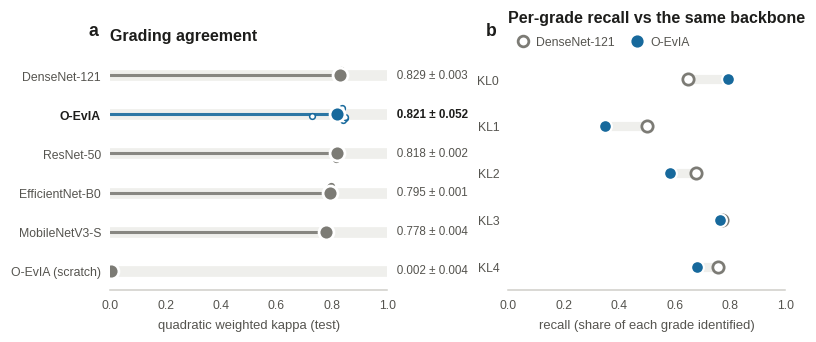

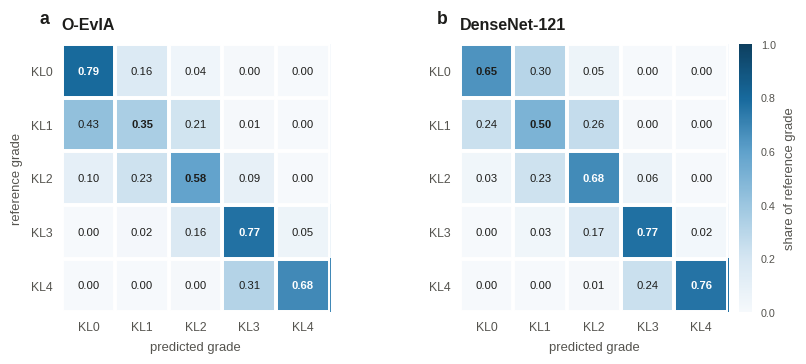

'/content/drive/MyDrive/EvIA_Knee/results/fig_confusion.png'

In [ ]:
NAMES = {"EvIA-KL": "O-EvIA", "EvIA-KL scratch": "O-EvIA (scratch)",
         "efficientnetb0": "EfficientNet-B0", "densenet121": "DenseNet-121",
         "resnet50": "ResNet-50", "mobilenetv3s": "MobileNetV3-S"}
KL = [f"KL{k}" for k in range(5)]


def load_p(tag, seeds):
    out = []
    for s in seeds:
        f = os.path.join(CFG.out_dir, f"preds_{tag}_seed{s}.npz")
        if os.path.exists(f):
            out.append(np.load(f)["p"])
    return out


def recall_by_grade(ps):
    return np.mean([[(E.decode(p)[Yte == k] == k).mean() for k in range(5)] for p in ps], 0)


def confusion(ps):
    CM = np.zeros((5, 5))
    for p in ps:
        np.add.at(CM, (Yte, E.decode(p)), 1)
    return CM / CM.sum(1, keepdims=True)


P_EV, P_DN = load_p("eviakl", CFG.seeds), load_p("densenet121", CFG.seeds[:3])

# Figure A: agreement and per-grade recall
g = ALL.groupby("tag").qwk
tags = list(g.mean().index)
fig, ax = V.figure(1, 2, width=7.2, height=3.0)
V.lollipop(ax[0], [NAMES.get(t, t) for t in tags], g.mean().values, g.std().values,
           seeds=[ALL[ALL.tag == t].qwk.values for t in tags], highlight="O-EvIA",
           xlabel="quadratic weighted kappa (test)")
ax[0].set_title("Grading agreement")
if P_DN:
    hs = V.dumbbell(ax[1], KL, recall_by_grade(P_DN), recall_by_grade(P_EV),
                    name_a="DenseNet-121", name_b="O-EvIA", xlim=(0, 1),
                    xlabel="recall (share of each grade identified)")
    V.legend(ax[1], handles=hs, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax[1].set_title("Per-grade recall vs the same backbone", pad=22)
V.panel_letters(ax)
V.save(fig, "fig_grading", CFG.out_dir)

# Figure B: confusion matrices, EvIA-KL next to its own backbone
fig, ax = V.figure(1, 2, width=7.2, height=3.2)
V.heatmap(ax[0], confusion(P_EV), KL, KL, cbar=False)
ax[0].set(xlabel="predicted grade", ylabel="reference grade", title="O-EvIA")
if P_DN:
    V.heatmap(ax[1], confusion(P_DN), KL, KL, cbar_label="share of reference grade")
    ax[1].set(xlabel="predicted grade", title="DenseNet-121")
V.panel_letters(ax)
V.save(fig, "fig_confusion", CFG.out_dir)